###Bước 1) Đọc dữ liệu và khảo sát

In [1]:
def in_thong_tin():
    print("Họ và tên: Nguyễn Gia Huy")
    print("Mã sinh viên: 6451071027")
    print("-" * 30)

in_thong_tin()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

bc = load_breast_cancer()
X = bc.data
y = bc.target                      # sklearn: 0 = malignant (ác tính), 1 = benign (lành tính)

df = pd.DataFrame(X, columns=bc.feature_names)
df['diagnosis'] = pd.Series(y).map({0: 'malignant', 1: 'benign'})

print("Kích thước X:", X.shape)
print("Các lớp:", bc.target_names)
print("\nSố mẫu mỗi lớp:")
print(df['diagnosis'].value_counts())
print("\nSố giá trị thiếu:", df.isnull().sum().sum())
print("\nMột số thuộc tính đầu:")
print(df.iloc[:, :6].describe().round(3))

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Kích thước X: (569, 30)
Các lớp: ['malignant' 'benign']

Số mẫu mỗi lớp:
diagnosis
benign       357
malignant    212
Name: count, dtype: int64

Số giá trị thiếu: 0

Một số thuộc tính đầu:
       mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
count      569.000       569.000         569.000    569.000          569.000   
mean        14.127        19.290          91.969    654.889            0.096   
std          3.524         4.301          24.299    351.914            0.014   
min          6.981         9.710          43.790    143.500            0.053   
25%         11.700        16.170          75.170    420.300            0.086   
50%         13.370        18.840          86.240    551.100            0.096   
75%         15.780        21.800         104.100    782.700            0.105   
max         28.110        39.280         188.500   2501.000            0.163   

       me

###Bước 2) Chuẩn hóa dữ liệu

In [2]:
in_thong_tin()
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(X)

print("Trung bình sau chuẩn hóa (làm tròn):", np.round(X_scaled.mean(axis=0)[:5], 3))
print("Độ lệch chuẩn sau chuẩn hóa       :", np.round(X_scaled.std(axis=0)[:5], 3))

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Trung bình sau chuẩn hóa (làm tròn): [-0. -0. -0. -0.  0.]
Độ lệch chuẩn sau chuẩn hóa       : [1. 1. 1. 1. 1.]


###Bước 3) Gom cụm k-Means với k = 2

In [3]:
in_thong_tin()
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
kmeans.fit(X_scaled)
cum = kmeans.labels_

print("Số mẫu mỗi cụm:", np.bincount(cum))
print("Inertia:", round(kmeans.inertia_, 2))

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Số mẫu mỗi cụm: [375 194]
Inertia: 11595.53


###Bước 4) Đối chiếu cụm với chẩn đoán thực tế

In [4]:
in_thong_tin()

bang = pd.crosstab(cum, df['diagnosis'], rownames=['Cụm'], colnames=['Chẩn đoán thực'])
print(bang)

# Gán nhãn theo đa số: cụm nào chứa nhiều ác tính hơn thì là "malignant"
anh_xa = {}
for c in [0, 1]:
    so_ac_tinh = ((cum == c) & (y == 0)).sum()
    so_lanh_tinh = ((cum == c) & (y == 1)).sum()
    anh_xa[c] = 0 if so_ac_tinh > so_lanh_tinh else 1   # 0 = malignant, 1 = benign

print("\nÁnh xạ cụm -> nhãn:", {c: bc.target_names[v] for c, v in anh_xa.items()})

y_pred = np.array([anh_xa[c] for c in cum])

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Chẩn đoán thực  benign  malignant
Cụm                              
0                  339         36
1                   18        176

Ánh xạ cụm -> nhãn: {0: np.str_('benign'), 1: np.str_('malignant')}


###Bước 5) Đánh giá bằng Accuracy, Precision, Recall, F1-score

In [5]:
in_thong_tin()
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", round(accuracy_score(y, y_pred), 4))
print(classification_report(y, y_pred, target_names=bc.target_names, digits=4))

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Accuracy: 0.9051
              precision    recall  f1-score   support

   malignant     0.9072    0.8302    0.8670       212
      benign     0.9040    0.9496    0.9262       357

    accuracy                         0.9051       569
   macro avg     0.9056    0.8899    0.8966       569
weighted avg     0.9052    0.9051    0.9042       569



###Bước 6) Confusion matrix bằng heatmap

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


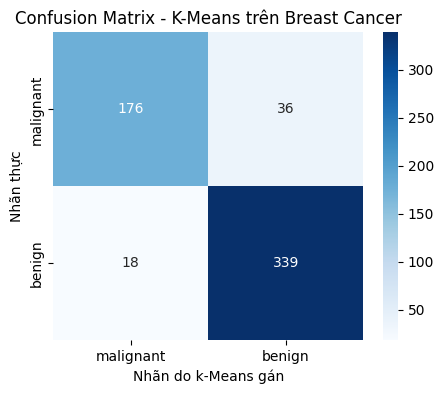

In [6]:
in_thong_tin()
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=bc.target_names, yticklabels=bc.target_names)
plt.xlabel('Nhãn do k-Means gán'); plt.ylabel('Nhãn thực')
plt.title('Confusion Matrix - K-Means trên Breast Cancer')
plt.show()

###Bước 7) Các độ đo chất lượng gom cụm

In [7]:
in_thong_tin()
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

print("Silhouette            :", round(silhouette_score(X_scaled, cum), 4))
print("Adjusted Rand (ARI)   :", round(adjusted_rand_score(y, cum), 4))
print("Normalized MI (NMI)   :", round(normalized_mutual_info_score(y, cum), 4))

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Silhouette            : 0.3434
Adjusted Rand (ARI)   : 0.6536
Normalized MI (NMI)   : 0.5324


###Bước 8) Trực quan hóa cụm bằng PCA 2 chiều

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Tỷ lệ phương sai giữ lại: [0.443 0.19 ] | tổng: 0.632


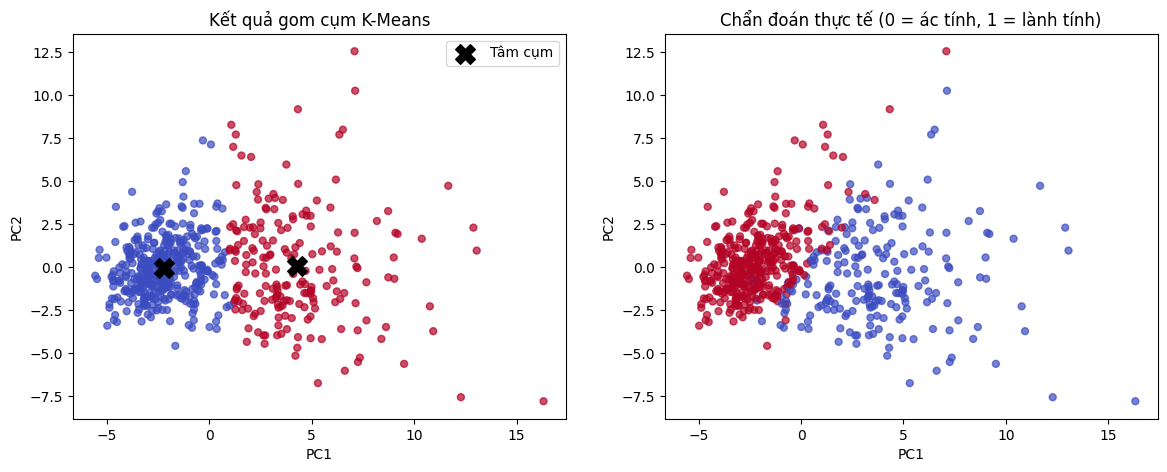

In [8]:
in_thong_tin()
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_scaled)
tam_2d = pca.transform(kmeans.cluster_centers_)
print("Tỷ lệ phương sai giữ lại:", pca.explained_variance_ratio_.round(3),
      "| tổng:", round(pca.explained_variance_ratio_.sum(), 3))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(X_2d[:, 0], X_2d[:, 1], c=cum, cmap='coolwarm', s=25, alpha=0.7)
ax[0].scatter(tam_2d[:, 0], tam_2d[:, 1], c='black', marker='X', s=200, label='Tâm cụm')
ax[0].set_title('Kết quả gom cụm K-Means'); ax[0].legend()

ax[1].scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap='coolwarm', s=25, alpha=0.7)
ax[1].set_title('Chẩn đoán thực tế (0 = ác tính, 1 = lành tính)')

for a in ax:
    a.set_xlabel('PC1'); a.set_ylabel('PC2')
plt.show()

###Bước 9) Xác định số cụm bằng Elbow

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


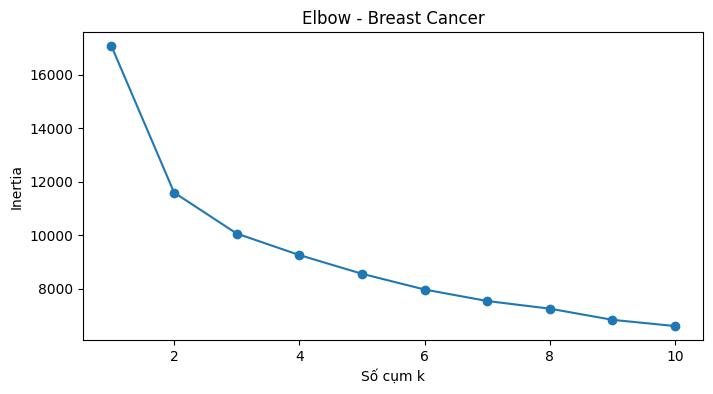

In [9]:
in_thong_tin()

inertia = []
for k in range(1, 11):
    inertia.append(KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled).inertia_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), inertia, 'o-')
plt.xlabel('Số cụm k'); plt.ylabel('Inertia')
plt.title('Elbow - Breast Cancer')
plt.show()